# Влияние типа передаваемой информации на эффективность групповой работы агентов искусственного интеллекта

## Сравнение планов и готовых текстов



## 1. Введение и цель работы

При работе в группе агенты могут выбрать одну и ту же тему. Тогда другой раздел останется пустым.

Я сравнил два способа общения между тремя агентами. В первом случае они сообщают друг другу планы. Во втором случае они передают уже готовые тексты.

Я хотел узнать, какой способ помогает лучше распределить работу. Для этого я проверил полноту ответа, сходство текстов, время и число токенов.

Все агенты обращались к одной локальной модели. У каждого был отдельный запрос. Они получали только те сообщения, которые разрешал выбранный способ работы.


## 2. Гипотеза

Я ожидал, что готовые тексты помогут агентам понять, что уже сделано. Следующий агент сможет выбрать другую тему. Тогда группа чаще заполнит все разделы.

Я также ожидал меньшего дублирования. Предположение о почти нулевом дублировании нужно проверить по данным. Его нельзя считать заранее выполненным.

Время и расход токенов я сравнивал отдельно. У способов разное число обращений к модели. Это влияет на затраты.


## 3. Задача для агентов

Группа должна предложить семейный автомобиль для заданных условий. В сценарии указаны бюджет, город, состав семьи, возраст детей и годовой пробег. Также есть особые пожелания.

Я подготовил 25 разных сценариев. Бюджеты составляют от 800 тысяч до 5 миллионов рублей. Есть крупные города и небольшие населённые пункты. Все сценарии относятся к семейным автомобилям.

Группа должна раскрыть три темы.

1. Цена и бюджет. Нужно описать цену машины и расходы на покупку.
2. Комфорт и практичность. Нужно оценить места в салоне, багажник, удобство для семьи и расход топлива.
3. Надёжность и обслуживание. Нужно описать надёжность, расходы на сервис и доступность запчастей.



## 4. Порядок работы

### Способ А. Намерения

В первом раунде каждый агент читает задачу и выбирает один раздел. Он пишет только короткий план. Чужих планов на этом шаге он не видит.

Во втором раунде каждый агент получает задачу и все три плана. Он может изменить свой выбор. После этого он пишет один финальный текст. Финальные тексты остальных агентов ему недоступны. Между раундами программа ждёт завершения всех трёх запросов.

Всего получается шесть обращений к модели.

### Способ Б. Факты

Первый агент сразу пишет один раздел. Второй получает его готовый текст и выбирает ещё не раскрытую тему. Третий получает оба предыдущих ответа и пишет свой раздел.

Программа просит выбрать оставшуюся тему. Она не исправляет выбор модели. Если агент повторяет чужой раздел, этот повтор остаётся в данных.

Всего получается три обращения к модели.



## 5. Как я считал показатели

### Полнота

Я засчитывал раздел, если хотя бы один его текст содержит не менее 100 знаков и слово по теме. Программа ищет части слов. Для цены подходят руб, бюджет, стоим и цен. Для комфорта подходят багаж, мест, расход, вместим и кресл. Для надёжности подходят надежн, обслуж, запчаст и ремонт.

Перед проверкой буква ё заменяется на е. Длина считается после удаления пробелов по краям. Два коротких ответа не складываются в один длинный. Итоговая полнота принимает значение от 0 до 3.

Это простая проверка. Она может засчитать формальный текст. Поэтому показатель не доказывает, что совет полезен и верен.

### Дублирование

Для сравнения я использовал модель из библиотеки Sentence Transformers. Она представляет текст в виде числового вектора. Затем программа считает косинусное сходство для каждой пары ответов. Для трёх агентов получается три пары. Я беру среднее по этим парам. Так оценка учитывает всю группу.

Высокое значение показывает большее сходство. Значение находится от минус одного до одного. Значение косинуса не является процентом повторного текста. Общая тема про автомобиль тоже повышает сходство. Длинные тексты разбиваются на части, чтобы оценка учитывала не только начало ответа.

### Время

Я измерял время всего способа. Для намерений сюда входят оба раунда. Для фактов сюда входят все три последовательных ответа. Время прогрева, расчёта показателей и записи файлов отдельно не добавлялось к этому показателю.

Счётчик измеряет прошедшее время. Поэтому в него может попасть пауза компьютера. Такие случаи я отдельно разобрал ниже.

### Токены

Токен является элементом текста, который обрабатывает модель. Это может быть часть слова или символ. Я сложил входные и выходные токены всех обращений. У намерений учтён и раунд планирования.

Счётчики взяты из ответов Ollama. В этом опыте оценка по длине текста не понадобилась.


## 6. Условия опыта

Я запускал модель локально через Ollama.

<table style="border-collapse:collapse;text-align:left"><thead><tr><th>Параметр</th><th>Значение</th></tr></thead><tbody><tr><td>Модель</td><td>mistral:7b</td></tr><tr><td>Квантование</td><td>Q4_K_M</td></tr><tr><td>Версия Ollama</td><td>0.40.15</td></tr><tr><td>Температура</td><td>0.7</td></tr><tr><td>Seed</td><td>42</td></tr><tr><td>Окно контекста</td><td>4096</td></tr><tr><td>Лимит ответа в токенах</td><td>900</td></tr><tr><td>Повторов каждого сценария</td><td>1</td></tr><tr><td>Одновременных вычислений в Ollama</td><td>1</td></tr><tr><td>Процессор</td><td>Intel Core i5-4440 @ 3.10GHz</td></tr><tr><td>Видеокарта</td><td>NVIDIA GeForce GTX 970</td></tr><tr><td>Память компьютера в ГиБ</td><td>16</td></tr><tr><td>Режим вычисления</td><td>Vulkan + CPU</td></tr><tr><td>Модель для сравнения текстов</td><td>sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2</td></tr></tbody></table>

## 7. Расчёт сводных показателей

Я считаю среднее, медиану и стандартное отклонение. Среднее показывает общий уровень показателя. Медиана является серединой упорядоченного набора. Она меньше зависит от одного очень долгого прогона. Стандартное отклонение показывает разброс результатов.


In [ ]:
import csv
import html
import json
import math
import os
from collections import defaultdict
from pathlib import Path
from statistics import mean, median, stdev


ROOT = Path(os.environ.get("COURSE_ROOT", Path.cwd())).resolve()
RESULTS = Path(os.environ.get("COURSE_RESULTS", str(ROOT / "results.csv"))).resolve()
META_FILE = RESULTS.with_suffix(".meta.json")
FIGURES = RESULTS.parent / "figures" / RESULTS.stem
CACHE = Path(os.environ.get("COURSE_CACHE_DIR", "E:/hf_cache/notebook"))
CACHE.mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(CACHE / "matplotlib")

import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from IPython.display import HTML, Markdown, display

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "figure.dpi": 110})
FIGURES.mkdir(parents=True, exist_ok=True)

with RESULTS.open(encoding="utf-8-sig", newline="") as stream:
    rows = list(csv.DictReader(stream))
meta = json.loads(META_FILE.read_text(encoding="utf-8-sig"))

required = {"scenario_id", "method", "repeat", "status", "coverage", "duplication_score",
            "time_sec", "tokens", "config_hash"}

keys = [(row["scenario_id"], row["method"], row["repeat"]) for row in rows]

METHODS = ["intentions", "facts"]
LABELS = {"intentions": "Намерения", "facts": "Факты"}

by_pair = defaultdict(dict)
for row in rows:
    if row["status"] in {"ok", "invalid_output"}:
        by_pair[(row["scenario_id"], int(row["repeat"]))][row["method"]] = row
paired = {key: value for key, value in by_pair.items() if all(m in value for m in METHODS)}



def fmt(value, digits=3):
    return "Нет данных" if value is None else f"{value:.{digits}f}".replace(".", ",")


def show_table(headers, values):

    head = "".join("<th>" + html.escape(str(x)) + "</th>" for x in headers)
    body = "".join("<tr>" + "".join("<td>" + html.escape(str(x)) + "</td>" for x in row)
                   + "</tr>" for row in values)
    display(HTML('<table style="border-collapse:collapse;text-align:left">'
                 + "<thead><tr>" + head + "</tr></thead><tbody>" + body + "</tbody></table>"))


In [ ]:
METRICS = [
    ("coverage", "Полнота", "Разделов из трёх"),
    ("duplication_score", "Сходство текстов", "Косинусное сходство"),
    ("time_sec", "Полное время", "Секунды"),
    ("tokens", "Расход токенов", "Входные и выходные токены"),
]


def number(value):
    if value in (None, ""):
        return None
    result = float(value)
    return result


scenario_values, pair_counts, summary = {}, {}, []
for metric, title, unit in METRICS:
    grouped = defaultdict(lambda: defaultdict(list))
    used_pairs = 0
    for (scenario_id, repeat), group in paired.items():
        values = {method: number(group[method][metric]) for method in METHODS}
        if any(v is None for v in values.values()):
            continue
        used_pairs += 1
        for method in METHODS:
            grouped[scenario_id][method].append(values[method])
    data = {sid: {m: mean(group[m]) for m in METHODS} for sid, group in grouped.items()}
    scenario_values[metric], pair_counts[metric] = data, used_pairs
    for method in METHODS:
        values = [group[method] for group in data.values()]
        summary.append({"metric": metric, "method": method, "n_scenarios": len(values),
                        "n_pairs": used_pairs, "mean": mean(values) if values else None,
                        "median": median(values) if values else None,
                        "std": stdev(values) if len(values) > 1 else None})

stats = {(r["metric"], r["method"]): r for r in summary}
means = {(key, method): stats[(key, method)]["mean"] for key, _, _ in METRICS for method in METHODS}
show_table(["Показатель", "Намерения, среднее", "Факты, среднее", "Сценариев"], [
    [title, fmt(means[(key, "intentions")]), fmt(means[(key, "facts")]),
     stats[(key, "intentions")]["n_scenarios"]] for key, title, _ in METRICS
])
summary_csv = RESULTS.with_name(RESULTS.stem + "_summary.csv")
with summary_csv.open("w", encoding="utf-8-sig", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(summary[0]))
    writer.writeheader()
    writer.writerows(summary)


def plot_metric(key, title, unit):
    data = scenario_values[key]
    if not data:
        display(Markdown("Для этого графика пока нет данных."))
        return
    fig, ax = plt.subplots(figsize=(7.6, 4.8), layout="constrained")
    ax.bar([0, 1], [mean([g[m] for g in data.values()]) for m in METHODS],
           width=0.55, color=["#4c78a8", "#f2a541"], alpha=0.65, zorder=2)
    for i, (sid, group) in enumerate(sorted(data.items())):
        shift = ((i % 9) - 4) * 0.014
        ax.plot([shift, 1 + shift], [group[m] for m in METHODS], color="#555555",
                alpha=0.3, marker="o", markersize=3, linewidth=0.7, zorder=3)
    ax.set_xticks([0, 1], [LABELS[m] for m in METHODS])
    ax.set_title(f"{title}. Сценариев {len(data)}")
    ax.set_ylabel(unit)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    if key == "coverage":
        ax.set_ylim(0, 3.3)
        ax.set_yticks([0, 1, 2, 3])
    elif key == "duplication_score":
        ax.set_ylim(-1.05, 1.05)
    else:
        ax.set_ylim(bottom=0)
    fig.savefig(FIGURES / f"{key}.png", dpi=180)
    plt.show()
    plt.close(fig)


Показатель,"Намерения, среднее","Факты, среднее",Сценариев
Полнота,"1,120","3,000",25
Сходство текстов,"0,845","0,651",25
Полное время,"216,162","251,706",25
Расход токенов,"5916,520","3335,440",25


## 8. Полнота ответа

На графике столбцы показывают средние значения. Каждая серая линия соединяет два результата одного сценария. Точки показывают отдельные наблюдения.


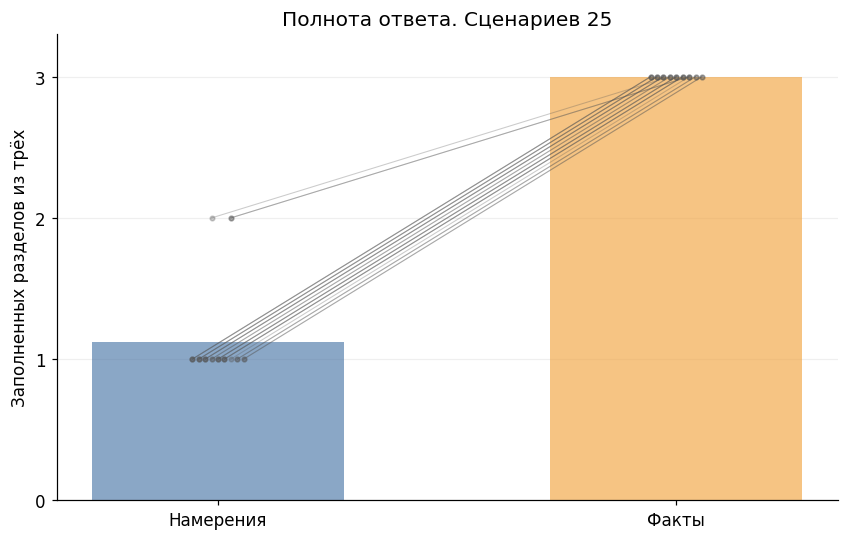

In [ ]:
plot_metric("coverage", "Полнота ответа", "Заполненных разделов из трёх")


In [ ]:
complete = {m: sum(int(group[m]["coverage"]) == 3 for group in paired.values()) for m in METHODS}
display(Markdown(
    f"Средняя полнота у намерений составила {fmt(means[('coverage','intentions')], 2)}. "
    f"У фактов она составила {fmt(means[('coverage','facts')], 2)}. "
    f"Все три раздела заполнены по выбранной проверке в {complete['facts']} из {len(paired)} прогонов с фактами. "
    f"У намерений таких прогонов было {complete['intentions']}.\n\n"
))


Средняя полнота у намерений составила 1,12. У фактов она составила 3,00. Все три раздела заполнены по выбранной проверке в 25 из 25 прогонов с фактами. У намерений таких прогонов было 0.



## 9. Сходство текстов

Здесь показано среднее сходство трёх пар финальных ответов. Более низкое значение соответствует меньшему сходству в рамках выбранной метрики.


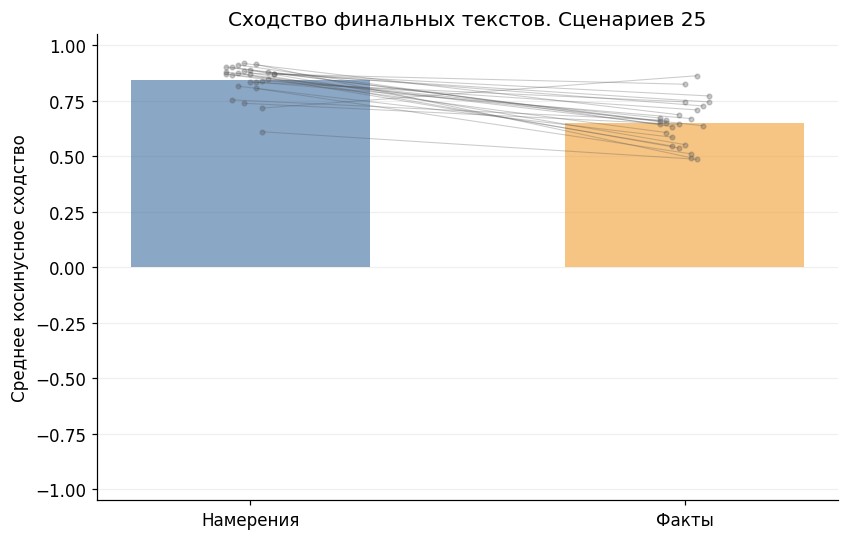

In [ ]:
plot_metric("duplication_score", "Сходство финальных текстов", "Среднее косинусное сходство")


In [ ]:
dup_a, dup_b = means[("duplication_score", "intentions")], means[("duplication_score", "facts")]
if dup_a is not None and dup_b is not None:
    direction = "ниже" if dup_b < dup_a else ("выше" if dup_b > dup_a else "такая же")
    display(Markdown(
        f"Средняя оценка у намерений равна {fmt(dup_a)}. У фактов она равна {fmt(dup_b)}. "
        f"Оценка фактов {direction}.\n\n"
        "В основном опыте сходство уменьшилось. При этом оно не стало близким к нулю. "
        "Поэтому ожидание почти нулевого дублирования не подтвердилось. "
    ))


Средняя оценка у намерений равна 0,845. У фактов она равна 0,651. Оценка фактов ниже.

В основном опыте сходство уменьшилось. При этом оно не стало близким к нулю. Поэтому ожидание почти нулевого дублирования не подтвердилось. 

## 11. Время работы

Первый график показывает полное измеренное время. Я оставил все значения. Долгие прогоны не удалялись и не заменялись более удобными числами.


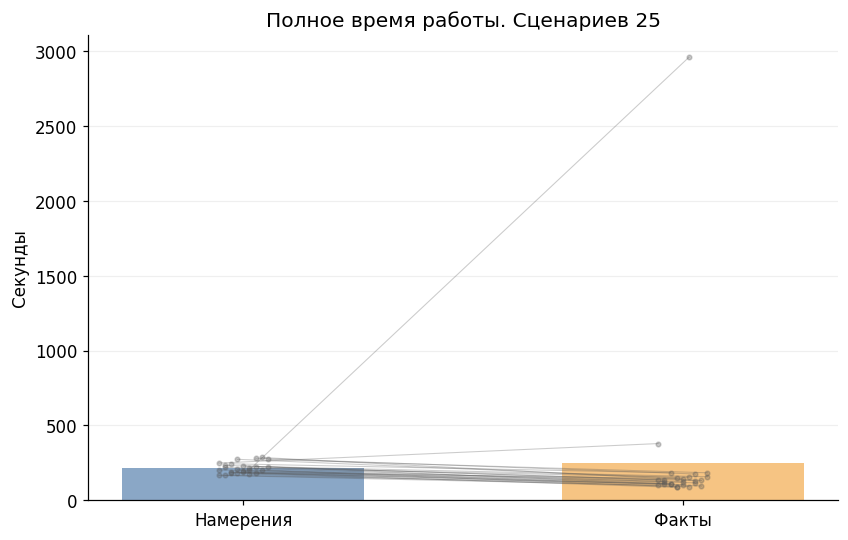

In [ ]:
plot_metric("time_sec", "Полное время работы", "Секунды")


Компьютер ушёл в спящий во время двух прогонов.

В основном опыте среднее время фактов оказалось выше среднего времени намерений. На него сильно повлиял сон компьютера. Медиана фактов оказалась ниже. Она лучше показывает середину этого набора, но не устраняет проблему условий опыта.

### Дополнительный график времени

Большое значение мешает рассмотреть остальные точки на обычной шкале. Поэтому я также использовал логарифмическую шкалу. Она позволяет показать короткие и длинные прогоны на одном графике.


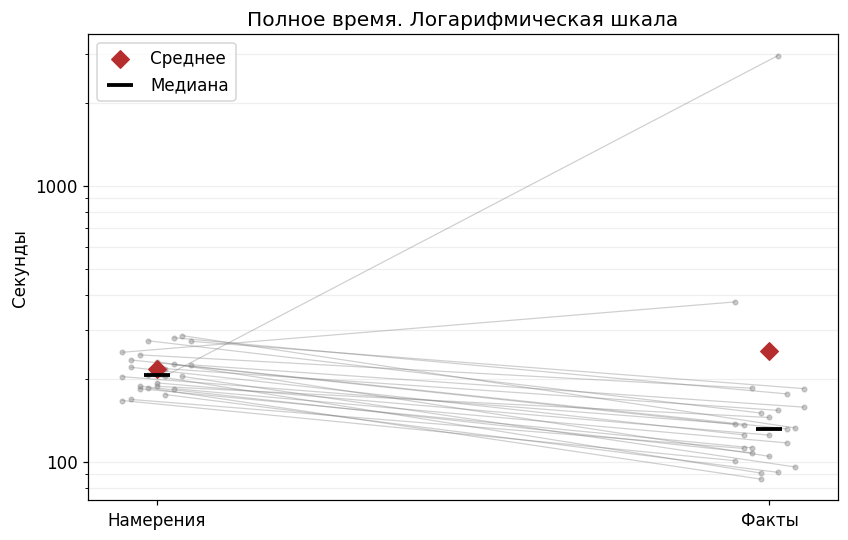

In [ ]:
data = scenario_values["time_sec"]
if data:
    fig, ax = plt.subplots(figsize=(7.6, 4.8), layout="constrained")
    for i, (sid, group) in enumerate(sorted(data.items())):
        shift = ((i % 9) - 4) * 0.014
        ax.plot([shift, 1 + shift], [group[m] for m in METHODS], color="#777777",
                alpha=0.35, marker="o", markersize=3, linewidth=0.8)
    ax.scatter([0, 1], [mean([g[m] for g in data.values()]) for m in METHODS],
               color="#b62d2d", marker="D", s=65, label="Среднее", zorder=4)
    ax.scatter([0, 1], [median([g[m] for g in data.values()]) for m in METHODS],
               color="black", marker="_", s=300, linewidth=2.5, label="Медиана", zorder=5)
    ax.set_yscale("log")
    from matplotlib.ticker import ScalarFormatter
    ax.yaxis.set_major_formatter(ScalarFormatter())
    ax.set_xticks([0, 1], [LABELS[m] for m in METHODS])
    ax.set_ylabel("Секунды")
    ax.set_title("Полное время. Логарифмическая шкала")
    ax.grid(axis="y", which="both", alpha=0.2)
    ax.legend(loc="upper left")
    fig.savefig(FIGURES / "time_sec_log.png", dpi=180)
    plt.show()
    plt.close(fig)


## 12. Расход токенов

На этом графике сложены входные и выходные токены. Переданные другим агентам планы и готовые тексты тоже входят в расход следующих запросов.


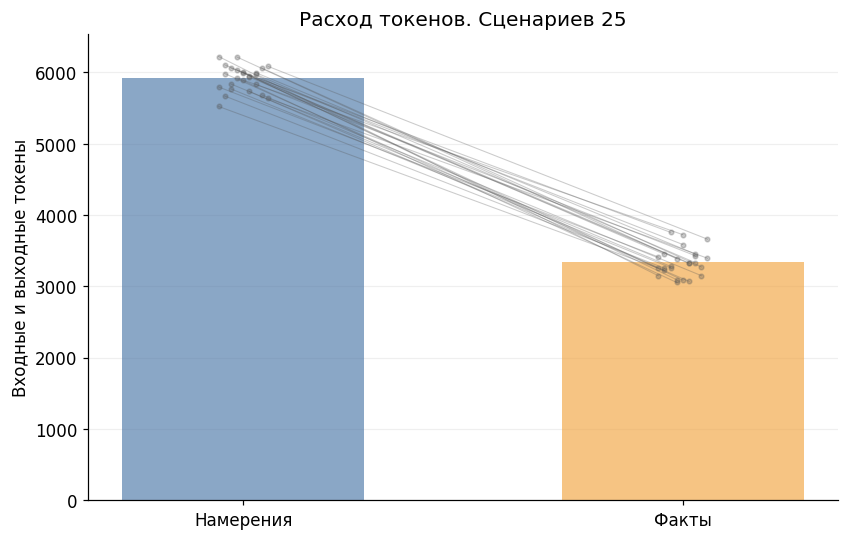

In [ ]:
plot_metric("tokens", "Расход токенов", "Входные и выходные токены")


Средний расход у намерений составил 5916,52 токена. У фактов он составил 3335,44 токена.

В основном опыте факты потребовали меньше токенов. У этого способа три вызова модели. У намерений их шесть.

## 15. Вывод

В этом опыте способ с фактами дал более высокую полноту и меньшее сходство текстов. Направление этих различий совпало с моей гипотезой.

Средняя полнота изменилась с 1,12 до 3,00. Среднее сходство изменилось с 0,845 до 0,651. Ожидание почти нулевого дублирования в основном опыте не подтвердилось.

По выбранной проверке факты закрыли все разделы во всех сценариях основного опыта. Факты потребовали меньше токенов. Вывод о скорости по среднему времени ограничен сном компьютера.
